# Actividad diagnóstica: flujo básico de Machine Learning con MLflow

- **Dataset:** PCOS (síndrome de ovario poliquístico), hoja `Full_new` de `PCOS_data_without_infertility.xlsx`.
- **Problema:** clasificación binaria. Predecir si una paciente tiene PCOS (`PCOS (Y/N)`: 0 = no, 1 = sí) a partir de datos clínicos, hormonales y de ultrasonido.
- **Modelo base (baseline):** Regresión Logística.

- **Alumna**: Lorena Trujillo Landeros
- **Matrícula**: A01797858

In [1]:
import os
os.environ.setdefault("MLFLOW_ENABLE_PROXY_MULTIPART_DOWNLOAD", "false")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature

### Carga de datos

In [2]:
# Importar datos

'''
- Importa los datos en un notebook.
- Describe su estructura (número de registros, variables, tipos y significado).
'''
pcos_data = pd.read_excel('PCOS_data_without_infertility.xlsx', sheet_name='Full_new')
# quita espacios sobrantes en los nombres
pcos_data.columns = pcos_data.columns.str.strip()

print(f"Registros: {pcos_data.shape[0]} | Columnas leídas: {pcos_data.shape[1]}\n")
pcos_data.info()


Registros: 541 | Columnas leídas: 45

<class 'pandas.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 45 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Sl. No                  541 non-null    int64  
 1   Patient File No.        541 non-null    int64  
 2   PCOS (Y/N)              541 non-null    int64  
 3   Age (yrs)               541 non-null    int64  
 4   Weight (Kg)             541 non-null    float64
 5   Height(Cm)              541 non-null    float64
 6   BMI                     541 non-null    float64
 7   Blood Group             541 non-null    int64  
 8   Pulse rate(bpm)         541 non-null    int64  
 9   RR (breaths/min)        541 non-null    int64  
 10  Hb(g/dl)                541 non-null    float64
 11  Cycle(R/I)              541 non-null    int64  
 12  Cycle length(days)      541 non-null    int64  
 13  Marraige Status (Yrs)   540 non-null    float64
 14  Pregnant(Y/N)  

In [3]:
print("--------- Cantidad de valores únicos de cada columna: ---------")
display(pcos_data.nunique())

--------- Cantidad de valores únicos de cada columna: ---------


Sl. No                    541
Patient File No.          541
PCOS (Y/N)                  2
Age (yrs)                  29
Weight (Kg)               117
Height(Cm)                 50
BMI                       355
Blood Group                 8
Pulse rate(bpm)            11
RR (breaths/min)            8
Hb(g/dl)                   46
Cycle(R/I)                  3
Cycle length(days)         12
Marraige Status (Yrs)      34
Pregnant(Y/N)               2
No. of aborptions           6
I   beta-HCG(mIU/mL)      307
II    beta-HCG(mIU/mL)    203
FSH(mIU/mL)               371
LH(mIU/mL)                342
FSH/LH                    512
Hip(inch)                  19
Waist(inch)                23
Waist:Hip Ratio            96
TSH (mIU/L)               308
AMH(ng/mL)                301
PRL(ng/mL)                481
Vit D3 (ng/mL)            331
PRG(ng/mL)                 89
RBS(mg/dl)                 55
Weight gain(Y/N)            2
hair growth(Y/N)            2
Skin darkening (Y/N)        2
Hair loss(

### Diccionario de Datos: PMOS / PCOS Dataset (`Full_new`)

**Fuente:** Hoja `Full_new` de `PCOS_data_without_infertility.xlsx`  
**Dimensiones:** 541 registros $\times$ 44 columnas 

| # | Columna original | Valores Únicos | Tipo analítico | Tipo original (`pandas`) | Tipo sugerido pipeline | Descripción y significado clínico / analítico |
| :---: | :--- | :---: | :--- | :--- | :--- | :--- |
| 1 | `Sl. No` | 541 | Identificador / Descarte | `int64` | Descartar | Número secuencial de registro. No aporta señal predictiva. |
| 2 | `Patient File No.` | 541 | Identificador / Descarte | `int64` | Descartar | Identificador de expediente clínico. Debe descartarse para evitar sobreajuste. |
| 3 | `PCOS (Y/N)` | 2 | **Categórica Binaria (Target)** | `int64` | `int64` / `category` | Variable objetivo. Diagnóstico clínico (0 = Negativo, 1 = Positivo). |
| 4 | `Age (yrs)` | 29 | Numérica Discreta | `int64` | `int64` | Edad de la paciente en años cumplidos. |
| 5 | `Weight (Kg)` | 117 | Numérica Continua | `float64` | `float64` | Peso corporal en kilogramos. |
| 6 | `Height(Cm)` | 50 | Numérica Continua | `float64` | `float64` | Estatura en centímetros. |
| 7 | `BMI` | 355 | Numérica Continua | `float64` | `float64` | Índice de masa corporal ($\text{kg/m}^2$). Factor de riesgo metabólico clave. |
| 8 | `Blood Group` | 8 | Categórica Nominal | `int64` | `category` / One-Hot | Grupo sanguíneo codificado (11 a 18). No tiene jerarquía ordinal. |
| 9 | `Pulse rate(bpm)` | 11 | Numérica Continua | `int64` | `float64` | Frecuencia cardíaca en reposo (latidos por minuto). |
| 10 | `RR (breaths/min)` | 8 | Numérica Continua | `int64` | `float64` | Frecuencia respiratoria (respiraciones por minuto). |
| 11 | `Hb(g/dl)` | 46 | Numérica Continua | `float64` | `float64` | Hemoglobina en sangre (g/dL). Permite evaluar anemia. |
| 12 | `Cycle(R/I)` | 3 | Categórica Nominal | `int64` | `category` | Regularidad del ciclo menstrual (2 = Regular, 4 = Irregular, 5 = Muy irregular). |
| 13 | `Cycle length(days)` | 12 | Numérica Discreta | `int64` | `int64` | Duración promedio del ciclo menstrual en días. |
| 14 | `Marraige Status (Yrs)` | 34 | Numérica Discreta | `float64` | `float64` | Años de matrimonio o vida en pareja. Presenta 1 valor nulo a imputar. |
| 15 | `Pregnant(Y/N)` | 2 | Categórica Binaria | `int64` | `category` | Antecedente o estado de embarazo previo (0 = No, 1 = Sí). |
| 16 | `No. of aborptions` | 6 | Numérica Discreta | `int64` | `int64` | Número de abortos previos experimentados. |
| 17 | `I   beta-HCG(mIU/mL)` | 307 | Numérica Continua | `float64` | `float64` | Primera medición de gonadotropina coriónica humana. |
| 18 | `II    beta-HCG(mIU/mL)` | 203 | Numérica Continua | `object` | `float64` | Segunda medición de beta-HCG. **Requiere limpieza:** convertir con `to_numeric(errors='coerce')`. |
| 19 | `FSH(mIU/mL)` | 371 | Numérica Continua | `float64` | `float64` | Hormona folículo estimulante. Regula el desarrollo folicular. |
| 20 | `LH(mIU/mL)` | 342 | Numérica Continua | `float64` | `float64` | Hormona luteinizante. Frecuentemente elevada en mujeres con PMOS/PCOS. |
| 21 | `FSH/LH` | 512 | Numérica Continua | `float64` | `float64` | Razón entre FSH y LH. Biomarcador diagnóstico de alteración ovulatoria. |
| 22 | `Hip(inch)` | 19 | Numérica Continua | `int64` | `float64` | Circunferencia de cadera en pulgadas. |
| 23 | `Waist(inch)` | 23 | Numérica Continua | `int64` | `float64` | Circunferencia de cintura en pulgadas. Indicador de adiposidad central. |
| 24 | `Waist:Hip Ratio` | 96 | Numérica Continua | `float64` | `float64` | Relación cintura-cadera. Predictor de riesgo metabólico y resistencia a insulina. |
| 25 | `TSH (mIU/L)` | 308 | Numérica Continua | `float64` | `float64` | Hormona estimulante de tiroides. Descarte de disfunción tiroidea. |
| 26 | `AMH(ng/mL)` | 301 | Numérica Continua | `object` | `float64` | Hormona antimülleriana (reserva ovárica). **Requiere limpieza:** convertir con `to_numeric(errors='coerce')` e imputar. |
| 27 | `PRL(ng/mL)` | 481 | Numérica Continua | `float64` | `float64` | Prolactina sérica en ng/mL. |
| 28 | `Vit D3 (ng/mL)` | 331 | Numérica Continua | `float64` | `float64` | Niveles de vitamina D3. Su deficiencia se asocia con resistencia a insulina. |
| 29 | `PRG(ng/mL)` | 89 | Numérica Continua | `float64` | `float64` | Progesterona sérica en ng/mL. |
| 30 | `RBS(mg/dl)` | 55 | Numérica Continua | `float64` | `float64` | Glucosa aleatoria en sangre (*Random Blood Sugar*). |
| 31 | `Weight gain(Y/N)` | 2 | Categórica Binaria | `int64` | `category` | Signo clínico: aumento de peso súbito o difícil de controlar (0 = No, 1 = Sí). |
| 32 | `hair growth(Y/N)` | 2 | Categórica Binaria | `int64` | `category` | Signo clínico: crecimiento de vello de patrón masculino / hirsutismo (0 = No, 1 = Sí). |
| 33 | `Skin darkening (Y/N)` | 2 | Categórica Binaria | `int64` | `category` | Signo clínico: oscurecimiento en pliegues cutáneos / acantosis nigricans (0 = No, 1 = Sí). |
| 34 | `Hair loss(Y/N)` | 2 | Categórica Binaria | `int64` | `category` | Signo clínico: caída difusa de cabello / alopecia androgénica (0 = No, 1 = Sí). |
| 35 | `Pimples(Y/N)` | 2 | Categórica Binaria | `int64` | `category` | Signo clínico: acné persistente moderado a severo (0 = No, 1 = Sí). |
| 36 | `Fast food (Y/N)` | 2 | Categórica Binaria | `float64` | `category` | Hábito dietético: consumo frecuente de comida rápida. Presenta 1 nulo a imputar. |
| 37 | `Reg.Exercise(Y/N)` | 2 | Categórica Binaria | `int64` | `category` | Estilo de vida: práctica regular de ejercicio físico (0 = No, 1 = Sí). |
| 38 | `BP _Systolic (mmHg)` | 6 | Numérica Continua | `int64` | `float64` | Presión arterial sistólica. Hay posibles valores atípicos/erróneos (ej. 12) a corregir. |
| 39 | `BP _Diastolic (mmHg)` | 5 | Numérica Continua | `int64` | `float64` | Presión arterial diastólica. Hay posibles valores atípicos/erróneos (ej. 8) a corregir. |
| 40 | `Follicle No. (L)` | 21 | Numérica Discreta | `int64` | `int64` | Conteo ecográfico de folículos antrales en ovario izquierdo. Alta relevancia diagnóstica. |
| 41 | `Follicle No. (R)` | 20 | Numérica Discreta | `int64` | `int64` | Conteo ecográfico de folículos antrales en ovario derecho. Alta relevancia diagnóstica. |
| 42 | `Avg. F size (L) (mm)` | 31 | Numérica Continua | `float64` | `float64` | Tamaño promedio de folículos en ovario izquierdo (mm). |
| 43 | `Avg. F size (R) (mm)` | 32 | Numérica Continua | `float64` | `float64` | Tamaño promedio de folículos en ovario derecho (mm). |
| 44 | `Endometrium (mm)` | 91 | Numérica Continua | `float64` | `float64` | Grosor de la pared endometrial evaluado por ecografía (mm). |

In [4]:
pcos_data.head(10)

,Sl. No,Patient File No.,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),...,Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm),Unnamed: 44
0,1,1,0,28,44.6,152.0,19.300000,15,78,22,...,1.0,0,110,80,3,3,18.0,18.0,8.5,NaN
1,2,2,0,36,65.0,161.5,24.921163,15,74,20,...,0.0,0,120,70,3,5,15.0,14.0,3.7,NaN
2,3,3,1,33,68.8,165.0,25.270891,11,72,18,...,1.0,0,120,80,13,15,18.0,20.0,10.0,NaN
3,4,4,0,37,65.0,148.0,29.674945,13,72,20,...,0.0,0,120,70,2,2,15.0,14.0,7.5,NaN
4,5,5,0,25,52.0,161.0,20.060954,11,72,18,...,0.0,0,120,80,3,4,16.0,14.0,7.0,NaN
5,6,6,0,36,74.1,165.0,27.217631,15,78,28,...,0.0,0,110,70,9,6,16.0,20.0,8.0,NaN
6,7,7,0,34,64.0,156.0,26.298488,11,72,18,...,0.0,0,120,80,6,6,15.0,16.0,6.8,NaN
7,8,8,0,33,58.5,159.0,23.139907,13,72,20,...,0.0,0,120,80,7,6,15.0,18.0,7.1,NaN
8,9,9,0,32,40.0,158.0,16.023073,11,72,18,...,0.0,0,120,80,5,7,17.0,17.0,4.2,NaN
9,10,10,0,36,52.0,150.0,23.111111,15,80,20,...,0.0,0,110,80,1,1,14.0,17.0,2.5,NaN


### Análisis exploratorio (EDA)

Se realiza una copia del dataset para realizar el análisis de la información. La limpieza con base en el análisis se realiza en el siguiente paso después del análisis.

In [5]:
# Copia numérica solo para explorar
eda = pcos_data.drop(columns=['Sl. No', 'Patient File No.'], errors='ignore')
eda = eda.loc[:, ~eda.columns.str.startswith('Unnamed')]
eda = eda.apply(pd.to_numeric, errors='coerce')          # texto no numérico -> NaN
eda_plot = eda.assign(Diagnóstico=eda['PCOS (Y/N)'].map({0: 'No PCOS', 1: 'PCOS'}))

# Estadísticas descriptivas
display(eda.describe().T.round(2))

print("\nValores faltantes por columna (incluye texto no numérico convertido a NaN):")
print(eda.isna().sum()[lambda s: s > 0])

,count,mean,std,min,25%,50%,75%,max
PCOS (Y/N),541.0,0.33,0.47,0.00,0.00,0.00,1.00,1.00
Age (yrs),541.0,31.43,5.41,20.00,28.00,31.00,35.00,48.00
Weight (Kg),541.0,59.64,11.03,31.00,52.00,59.00,65.00,108.00
Height(Cm),541.0,156.48,6.03,137.00,152.00,156.00,160.00,180.00
BMI,541.0,24.31,4.06,12.42,21.64,24.24,26.63,38.90
Blood Group,541.0,13.80,1.84,11.00,13.00,14.00,15.00,18.00
Pulse rate(bpm),541.0,73.25,4.43,13.00,72.00,72.00,74.00,82.00
RR (breaths/min),541.0,19.24,1.69,16.00,18.00,18.00,20.00,28.00
Hb(g/dl),541.0,11.16,0.87,8.50,10.50,11.00,11.70,14.80
Cycle(R/I),541.0,2.56,0.90,2.00,2.00,2.00,4.00,5.00



Valores faltantes por columna (incluye texto no numérico convertido a NaN):
Marraige Status (Yrs)     1
II    beta-HCG(mIU/mL)    1
AMH(ng/mL)                1
Fast food (Y/N)           1
dtype: int64


            registros     %
PCOS (Y/N)                 
0                 364  67.3
1                 177  32.7


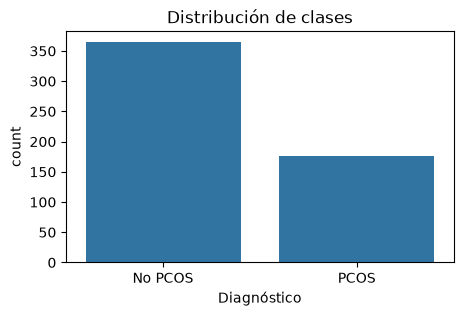

In [6]:
# 1. Distribución de la variable objetivo
conteo = eda['PCOS (Y/N)'].value_counts().sort_index()
porcentaje = (eda['PCOS (Y/N)'].value_counts(normalize=True).sort_index() * 100).round(1)
print(pd.DataFrame({'registros': conteo, '%': porcentaje}))

fig, ax = plt.subplots(figsize=(5, 3))
sns.countplot(data=eda_plot, x='Diagnóstico', order=['No PCOS', 'PCOS'], ax=ax)
ax.set_title('Distribución de clases')
plt.show()

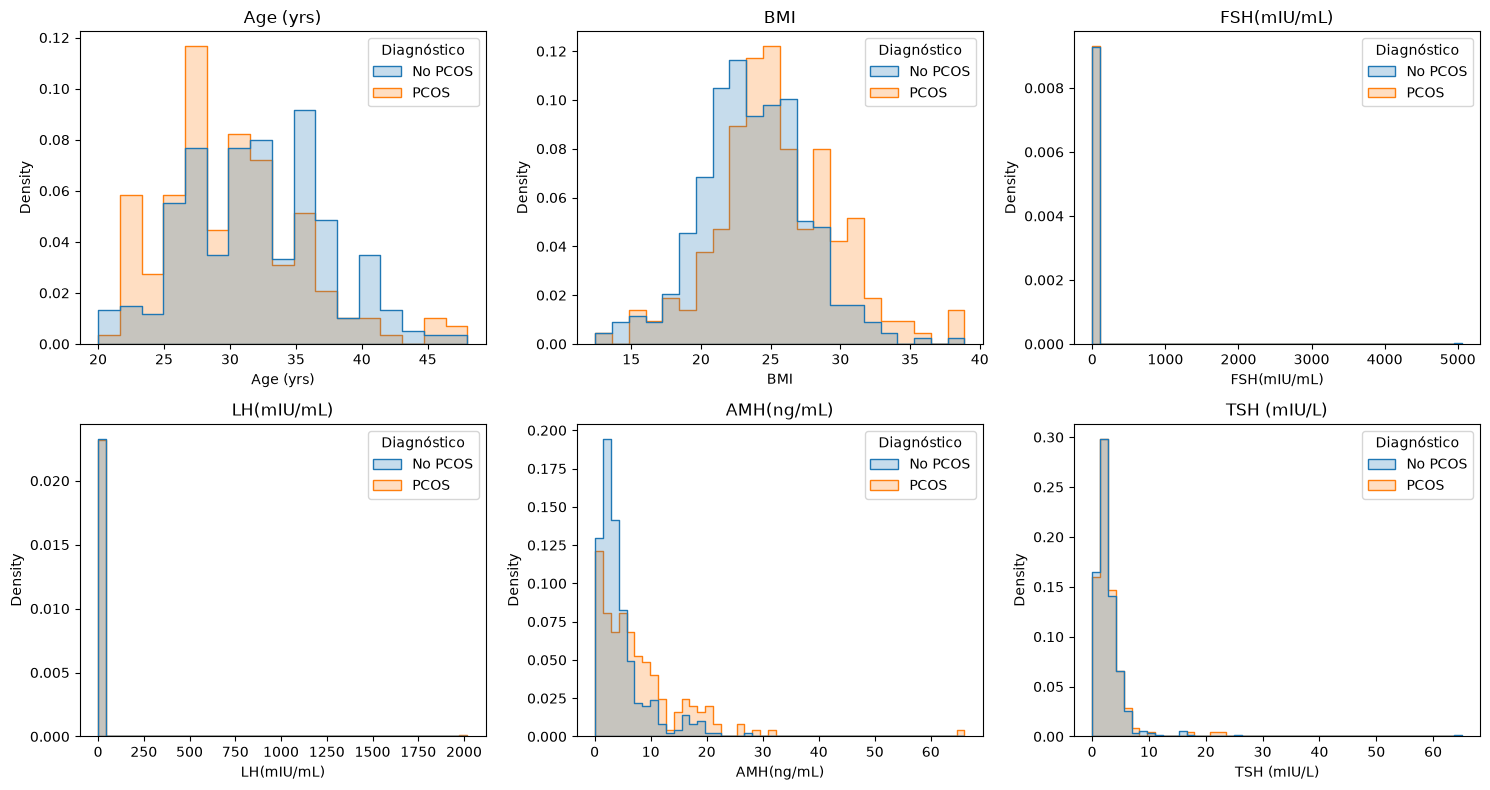

In [7]:
# Distribución de variables clave según el diagnóstico
vars_hist = ['Age (yrs)', 'BMI', 'FSH(mIU/mL)', 'LH(mIU/mL)', 'AMH(ng/mL)', 'TSH (mIU/L)']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), vars_hist):
    sns.histplot(data=eda_plot, x=col, hue='Diagnóstico', element='step',
                 stat='density', common_norm=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

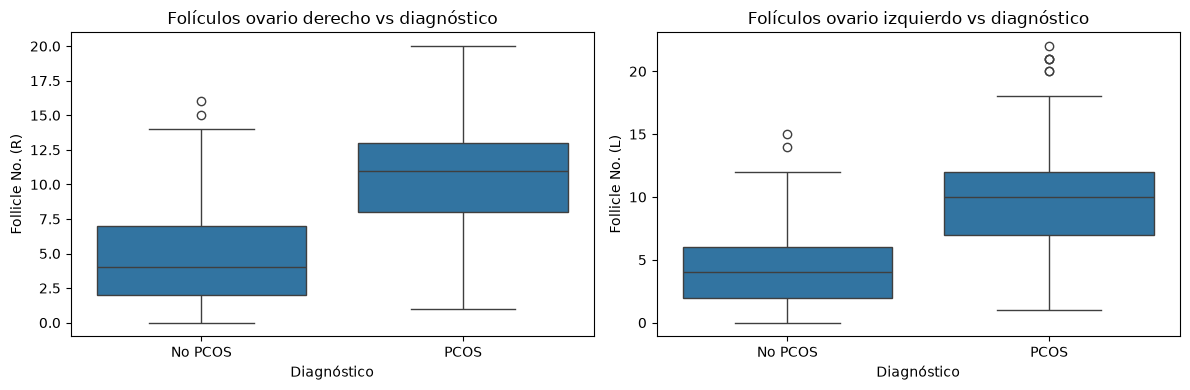

In [8]:
# 3. Conteo folicular vs diagnóstico
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=eda_plot, x='Diagnóstico', y='Follicle No. (R)', order=['No PCOS', 'PCOS'], ax=axes[0])
axes[0].set_title('Folículos ovario derecho vs diagnóstico')
sns.boxplot(data=eda_plot, x='Diagnóstico', y='Follicle No. (L)', order=['No PCOS', 'PCOS'], ax=axes[1])
axes[1].set_title('Folículos ovario izquierdo vs diagnóstico')
plt.tight_layout()
plt.show()

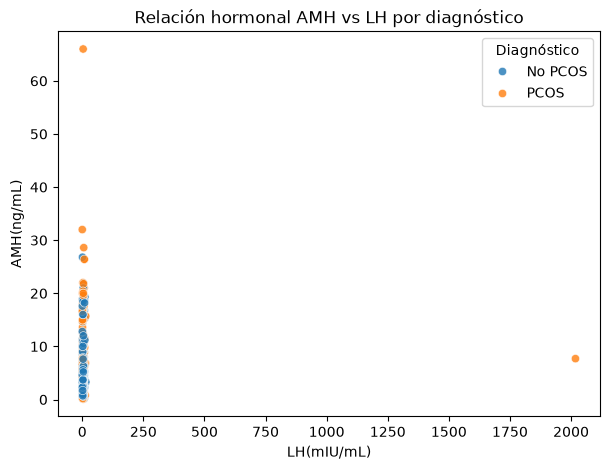

In [9]:
# 4. Relación hormonal AMH vs LH
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=eda_plot, x='LH(mIU/mL)', y='AMH(ng/mL)', hue='Diagnóstico', alpha=0.8, ax=ax)
ax.set_title('Relación hormonal AMH vs LH por diagnóstico')
plt.show()

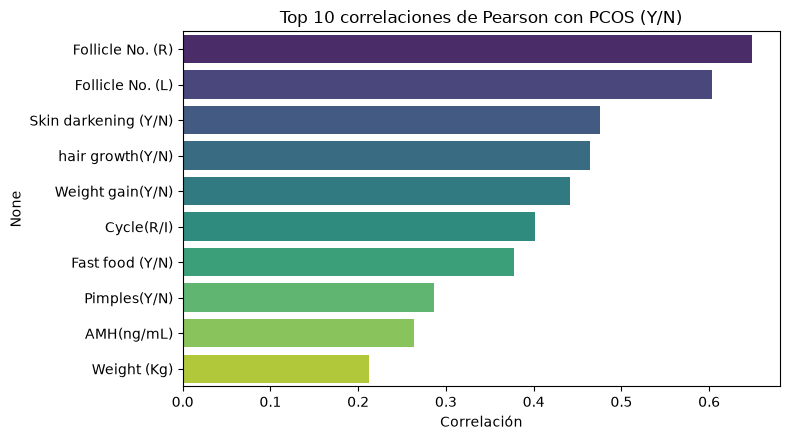

Mediana de folículos por diagnóstico:
            Follicle No. (L)  Follicle No. (R)
PCOS (Y/N)                                    
0                        4.0               4.0
1                       10.0              11.0


In [10]:
# 5. Variables más correlacionadas con el diagnóstico
corr = eda.corr(numeric_only=True)['PCOS (Y/N)'].drop('PCOS (Y/N)')
top_corr = corr.reindex(corr.abs().sort_values(ascending=False).index).head(10)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=top_corr.values, y=top_corr.index, hue=top_corr.index,
            palette='viridis', legend=False, ax=ax)
ax.set_title('Top 10 correlaciones de Pearson con PCOS (Y/N)')
ax.set_xlabel('Correlación')
plt.tight_layout()
plt.show()

print("Mediana de folículos por diagnóstico:")
print(eda.groupby('PCOS (Y/N)')[['Follicle No. (L)', 'Follicle No. (R)']].median())

### Conclusiones del análisis

- **Clase minoritaria.** El conteo de clases muestra que PCOS es la clase menos frecuente (PCOS 67.3, no PCOS 32.7). Se reportará *accuraccy*, *recall* y *F1*.
- **Escalas muy distintas.** Edad, hormonas, medidas corporales y conteos viven en rangos distintos (ver `describe()`), Se **escalarán** las variables numéricas para que la regresión logística converja y sus coeficientes sean comparables.
- **Valores extremos y valores imposibles.** Los histogramas muestran colas largas en varias hormonas y presiones arteriales fuera de rango fisiológico. Se revisan y se decide caso por caso en el paso de limpieza que se abordará más adelante.
- **Variables con mayor señal.** Las correlaciones y los boxplots muestran qué variables se separan más entre clases (típicamente el conteo folicular, el ciclo y algunas hormonas). Es una exploración univariada; el modelo evalúa el efecto conjunto.

### Limpieza de datos

In [11]:
# Limpieza de datos
'''
- Identifica y trata valores faltantes, duplicados, outliers y tipos incorrectos.
- Documenta cada decisión que tomes.
'''

filas_inicial = len(pcos_data)
df = pcos_data.copy()

print("\n3.1 Columnas sin valor predictivo")
cols_descartar = ['Sl. No', 'Patient File No.'] + [c for c in df.columns if c.startswith('Unnamed')]
df = df.drop(columns=cols_descartar)
print("Columnas descartadas:", cols_descartar)

print("\n3.2 Tipos incorrectos: columnas numéricas leídas como texto")
cols_texto = df.select_dtypes(include=['object', 'string']).columns.tolist()
print("\nColumnas de texto que deben ser numéricas:", cols_texto)
for col in cols_texto:
    original = df[col]
    df[col] = pd.to_numeric(original, errors='coerce')
    invalidos = original[df[col].isna() & original.notna()]
    print(f"    {col}: {len(invalidos)} valor(es) no numérico(s) convertido(s) a NaN -> {invalidos.unique().tolist()}")

print("\n3.3 Duplicados (se buscan sin los identificadores, que ya se descartaron)")
n_dup = int(df.duplicated().sum())
df = df.drop_duplicates()
print(f"\nRegistros duplicados eliminados: {n_dup}")

print("\n3.4 Valores fisiológicamente imposibles (presión arterial)")
print("\nPresiones arteriales imposibles:")
for col, minimo in [('BP _Systolic (mmHg)', 60), ('BP _Diastolic (mmHg)', 40)]:
    mask = df[col] < minimo
    print(f"    {col} < {minimo}: {int(mask.sum())} registro(s) -> se marcan como NaN")
    df.loc[mask, col] = np.nan

print("\n3.5 Valores atípicos (regla del rango intercuartílico). Solo se reportan, no se eliminan.")
continuas = [c for c in df.columns if c != 'PCOS (Y/N)' and df[c].nunique() > 10]
q1, q3 = df[continuas].quantile(0.25), df[continuas].quantile(0.75)
iqr = q3 - q1
n_atipicos = ((df[continuas] < q1 - 1.5 * iqr) | (df[continuas] > q3 + 1.5 * iqr)).sum()
print("Valores fuera de 1.5 x IQR por variable continua (solo las que tienen):")
print(n_atipicos[n_atipicos > 0].sort_values(ascending=False))

print("\n3.6 Valores faltantes después de las correcciones anteriores")
nulos = df.isna().sum()
print("\nValores faltantes por columna:")
print(nulos[nulos > 0])

pcos_clean = df.reset_index(drop=True)
print(f"\nResumen -> filas: {filas_inicial} -> {len(pcos_clean)} | columnas: {pcos_data.shape[1]} -> {pcos_clean.shape[1]}")


3.1 Columnas sin valor predictivo
Columnas descartadas: ['Sl. No', 'Patient File No.', 'Unnamed: 44']

3.2 Tipos incorrectos: columnas numéricas leídas como texto

Columnas de texto que deben ser numéricas: ['II    beta-HCG(mIU/mL)', 'AMH(ng/mL)']
    II    beta-HCG(mIU/mL): 1 valor(es) no numérico(s) convertido(s) a NaN -> ['1.99.']
    AMH(ng/mL): 1 valor(es) no numérico(s) convertido(s) a NaN -> ['a']

3.3 Duplicados (se buscan sin los identificadores, que ya se descartaron)

Registros duplicados eliminados: 0

3.4 Valores fisiológicamente imposibles (presión arterial)

Presiones arteriales imposibles:
    BP _Systolic (mmHg) < 60: 1 registro(s) -> se marcan como NaN
    BP _Diastolic (mmHg) < 40: 1 registro(s) -> se marcan como NaN

3.5 Valores atípicos (regla del rango intercuartílico). Solo se reportan, no se eliminan.
Valores fuera de 1.5 x IQR por variable continua (solo las que tienen):
Pulse rate(bpm)           94
II    beta-HCG(mIU/mL)    78
Cycle length(days)        77
AMH

### Decisiones de limpieza

| Problema | Decisión | Justificación |
| :-- | :-- | :-- |
| `Sl. No`, `Patient File No.` | Se descartan | Son identificadores; no tienen significado clínico y podrían inducir sobreajuste. |
| `Unnamed: 44` | Se descarta | Casi vacía; es un residuo del archivo Excel. |
| `AMH(ng/mL)` y `II    beta-HCG(mIU/mL)` como texto | `pd.to_numeric(errors='coerce')` | Son mediciones continuas. Los valores no numéricos (texto o errores de captura) se vuelven NaN para imputarse después, en lugar de inventar un valor. |
| Duplicados | Se buscan y se eliminan si existen (en este dataset no se encontró ninguno) | Un mismo registro repetido pesaría doble en el entrenamiento y podría pasar a prueba y entrenamiento a la vez. |
| Presión sistólica < 60 y diastólica < 40 | Se marcan como NaN | Son valores imposibles en pacientes, probablemente un error de captura. No se "adivina" el valor corregido. |
| Valores atípicos (IQR) | **No se eliminan** | El dataset es pequeño; eliminar filas quitaría casos reales de PCOS, y en hormonas las colas largas son normales. Se mitigan con imputación por mediana y escalado. Un escalador robusto o una transformación logarítmica quedan como mejora. |
| Valores faltantes | **No se borran filas**; se imputan dentro del *pipeline* | Mediana para numéricas y moda para categóricas, calculadas solo con el conjunto de entrenamiento. Así no se pierden datos y se evita fuga de información (*data leakage*). |

### Entrenar modelo

In [12]:
# 
'''
- Selecciona un modelo sencillo (baseline) apropiado para el problema.
- Divide los datos en entrenamiento y prueba, y entrénalo.
'''
RANDOM_STATE = 42
y = pcos_clean['PCOS (Y/N)']
X = pcos_clean.drop(columns=['PCOS (Y/N)'])

cols_categoricas = ['Blood Group', 'Cycle(R/I)']
cols_numericas = [c for c in X.columns if c not in cols_categoricas]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"Entrenamiento: {X_train.shape} | Prueba: {X_test.shape}")
print("Proporción de PCOS -> train: {:.1%} | test: {:.1%}".format(y_train.mean(), y_test.mean()))

preprocesamiento = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                      ('scaler', StandardScaler())]), cols_numericas),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cols_categoricas),
])

modelo = Pipeline([
    ('prep', preprocesamiento),
    ('logreg', LogisticRegression(solver='liblinear', max_iter=1000, random_state=RANDOM_STATE)),
])
modelo.fit(X_train, y_train)
print("Modelo entrenado.")

Entrenamiento: (432, 41) | Prueba: (109, 41)
Proporción de PCOS -> train: 32.6% | test: 33.0%
Modelo entrenado.


### Evaluar modelo

accuracy     0.899
precision    0.821
recall       0.889
f1           0.853
roc_auc      0.948

              precision    recall  f1-score   support

     No PCOS       0.94      0.90      0.92        73
        PCOS       0.82      0.89      0.85        36

    accuracy                           0.90       109
   macro avg       0.88      0.90      0.89       109
weighted avg       0.90      0.90      0.90       109



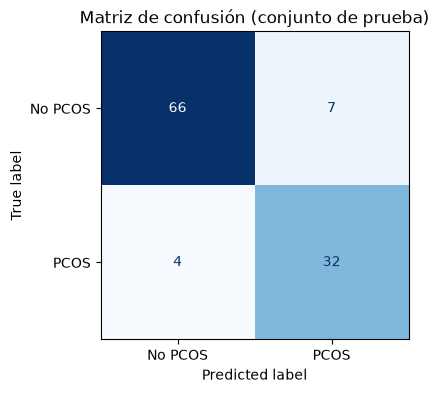

In [13]:
'''
Calcula al menos una métrica de desempeño coherente con el tipo de problema.
Interpreta el resultado de manera detallada.
'''
y_pred = modelo.predict(X_test)
y_proba = modelo.predict_proba(X_test)[:, 1]

metricas = {
    'accuracy': accuracy_score(y_test, y_pred),
    'precision': precision_score(y_test, y_pred, zero_division=0),
    'recall': recall_score(y_test, y_pred, zero_division=0),
    'f1': f1_score(y_test, y_pred, zero_division=0),
    'roc_auc': roc_auc_score(y_test, y_proba),
}
print(pd.Series(metricas).round(3).to_string())
print()
print(classification_report(y_test, y_pred, target_names=['No PCOS', 'PCOS'], zero_division=0))

cm = confusion_matrix(y_test, y_pred)
fig_cm, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm, display_labels=['No PCOS', 'PCOS']).plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Matriz de confusión (conjunto de prueba)')
plt.show()

In [14]:
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
acc_dummy = accuracy_score(y_test, dummy.predict(X_test))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_acc = cross_val_score(modelo, X, y, cv=cv, scoring='accuracy')
cv_rec = cross_val_score(modelo, X, y, cv=cv, scoring='recall')

tn, fp, fn, tp = cm.ravel()
print(f"De {len(y_test)} pacientes de prueba, el modelo clasificó bien a {tn + tp} ({metricas['accuracy']:.1%}).")
print(f"- Detectó {tp} de {tp + fn} casos con PCOS (recall = {metricas['recall']:.1%}); dejó {fn} sin detectar (falsos negativos).")
print(f"- Emitió {tp + fp} alertas de PCOS; {tp} fueron correctas (precision = {metricas['precision']:.1%}) y {fp} fueron falsas alarmas.")
print(f"- Un clasificador que siempre responde 'No PCOS' tendría accuracy = {acc_dummy:.1%}.")
print(f"- Validación cruzada (5 pliegues): accuracy = {cv_acc.mean():.3f} ± {cv_acc.std():.3f} | recall = {cv_rec.mean():.3f} ± {cv_rec.std():.3f}")

De 109 pacientes de prueba, el modelo clasificó bien a 98 (89.9%).
- Detectó 32 de 36 casos con PCOS (recall = 88.9%); dejó 4 sin detectar (falsos negativos).
- Emitió 39 alertas de PCOS; 32 fueron correctas (precision = 82.1%) y 7 fueron falsas alarmas.
- Un clasificador que siempre responde 'No PCOS' tendría accuracy = 67.0%.
- Validación cruzada (5 pliegues): accuracy = 0.891 ± 0.027 | recall = 0.814 ± 0.065


### Interpretación de los resultados

- *Accuracy*: proporción total de aciertos. Es fácil de leer, pero con clases desbalanceadas puede engañar; por eso se compara con el clasificador trivial que siempre predice la clase mayoritaria.
- *Recall* (sensibilidad): de las pacientes que sí tienen PCOS, qué fracción detecta el modelo. Es la métrica prioritaria en un contexto de tamizaje, porque un falso negativo es una paciente con PCOS que no se detecta.
- *Precision*: de las alertas que emite, qué fracción son correctas. Una precision baja implica más falsas alarmas, que en este caso significan estudios adicionales, no un daño directo.
- *F1* resume precision y recall; *AUC-ROC* mide qué tan bien el modelo ordena a las pacientes por probabilidad, sin depender de un umbral de decisión.

### Registro de experimento

In [15]:
'''
- Usa MLFlow Tracking para registrar parámetros y métricas.
- Solo si aplica, registra los artefactos del modelo base.
'''

mlflow.set_experiment("pcos_baseline")

params_logreg = modelo.named_steps['logreg'].get_params()

with mlflow.start_run(run_name="logreg_baseline") as run:
    mlflow.log_params({
        "model": "LogisticRegression",
        "solver": params_logreg['solver'],
        "C": params_logreg['C'],
        "max_iter": params_logreg['max_iter'],
        "scaler": "StandardScaler",
        "imputer_numeric": "median",
        "imputer_categorical": "most_frequent",
        "test_size": 0.2,
        "random_state": RANDOM_STATE,
        "n_features": X.shape[1],
        "n_train": len(X_train),
        "n_test": len(X_test),
        "duplicates_removed": n_dup,
    })
    mlflow.log_metrics({
        **metricas,
        "cv_accuracy_mean": cv_acc.mean(),
        "cv_recall_mean": cv_rec.mean(),
        "dummy_accuracy": acc_dummy,
    })
    mlflow.set_tags({
        "etapa": "baseline",
        "dataset": "PCOS_data_without_infertility.xlsx / Full_new",
    })
    mlflow.log_figure(fig_cm, "confusion_matrix.png")

    X_sig = X_train.astype('float64')    # columnas numéricas como float: el esquema tolera nulos
    mlflow.sklearn.log_model(
        modelo, name="model", serialization_format="cloudpickle",
        signature=infer_signature(X_sig, modelo.predict(X_train)),
        input_example=X_sig.head(3),
    )
    run_id = run.info.run_id

print("Run ID:", run_id)

2026/10/04 22:49:02 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Run ID: 634fda416b5e43329bd4917ca68a6a9a


In [16]:
registro = mlflow.get_run(run_id)
print(f"Run: {registro.info.run_name} | estado: {registro.info.status}")

print("\nParámetros registrados:")
display(pd.DataFrame({"valor": registro.data.params}))

print("Métricas registradas:")
display(pd.DataFrame({"valor": {k: round(v, 3) for k, v in registro.data.metrics.items()}}))

Run: logreg_baseline | estado: FINISHED

Parámetros registrados:


,valor
model,LogisticRegression
solver,liblinear
C,1.0
max_iter,1000
scaler,StandardScaler
imputer_numeric,median
imputer_categorical,most_frequent
test_size,0.2
random_state,42
n_features,41


Métricas registradas:


,valor
accuracy,0.899
precision,0.821
recall,0.889
f1,0.853
roc_auc,0.948
cv_accuracy_mean,0.891
cv_recall_mean,0.814
dummy_accuracy,0.670


### Reflexión

Hasta este punto de la maestría hemos aprendido como funcionan los modelos y como podemos aplicar fine-tuning e interpretar metricas pero no habíamos analizado como llevar completamente un modelo a producción y/o como realizar pruebas de forma automatizada, realizando registros de las ejecuciones en aplicaciones especializadas para comparar los mejores resultados y hacer ajustes a los modelos. Ahora, con el repaso de las bases de Machine Learning y teniendo el contexto de lo que es MLOps, podemos abordar esos temas. Aplicando prácticas de MLOps haría cuatro mejoras. 
- **reproducibilidad**: versionar el código con Git, fijar las dependencias en un archivo `environment.yml` y registrar en MLflow el hash del dataset, para poder repetir exactamente cada corrida. 
- **modularidad y automatización**: mover la limpieza, el entrenamiento y la evaluación a scripts o a un pipeline orquestado, con pruebas automáticas de calidad de datos (rangos válidos, tipos, nulos) que habrían detectado las presiones arteriales imposibles antes de entrenar. 
- **gestión del modelo**: usar el Model Registry de MLflow para versionar y promover modelos, y comparar corridas con validación cruzada y búsqueda de hiperparámetros en lugar de un solo corte entrenamiento/prueba. 
- **monitoreo**: vigilar el desempeño y la deriva de los datos en producción, sobre todo en un contexto de salud, donde un modelo que se degrada sin avisar tiene consecuencias reales.

### Evidencias Mlflow

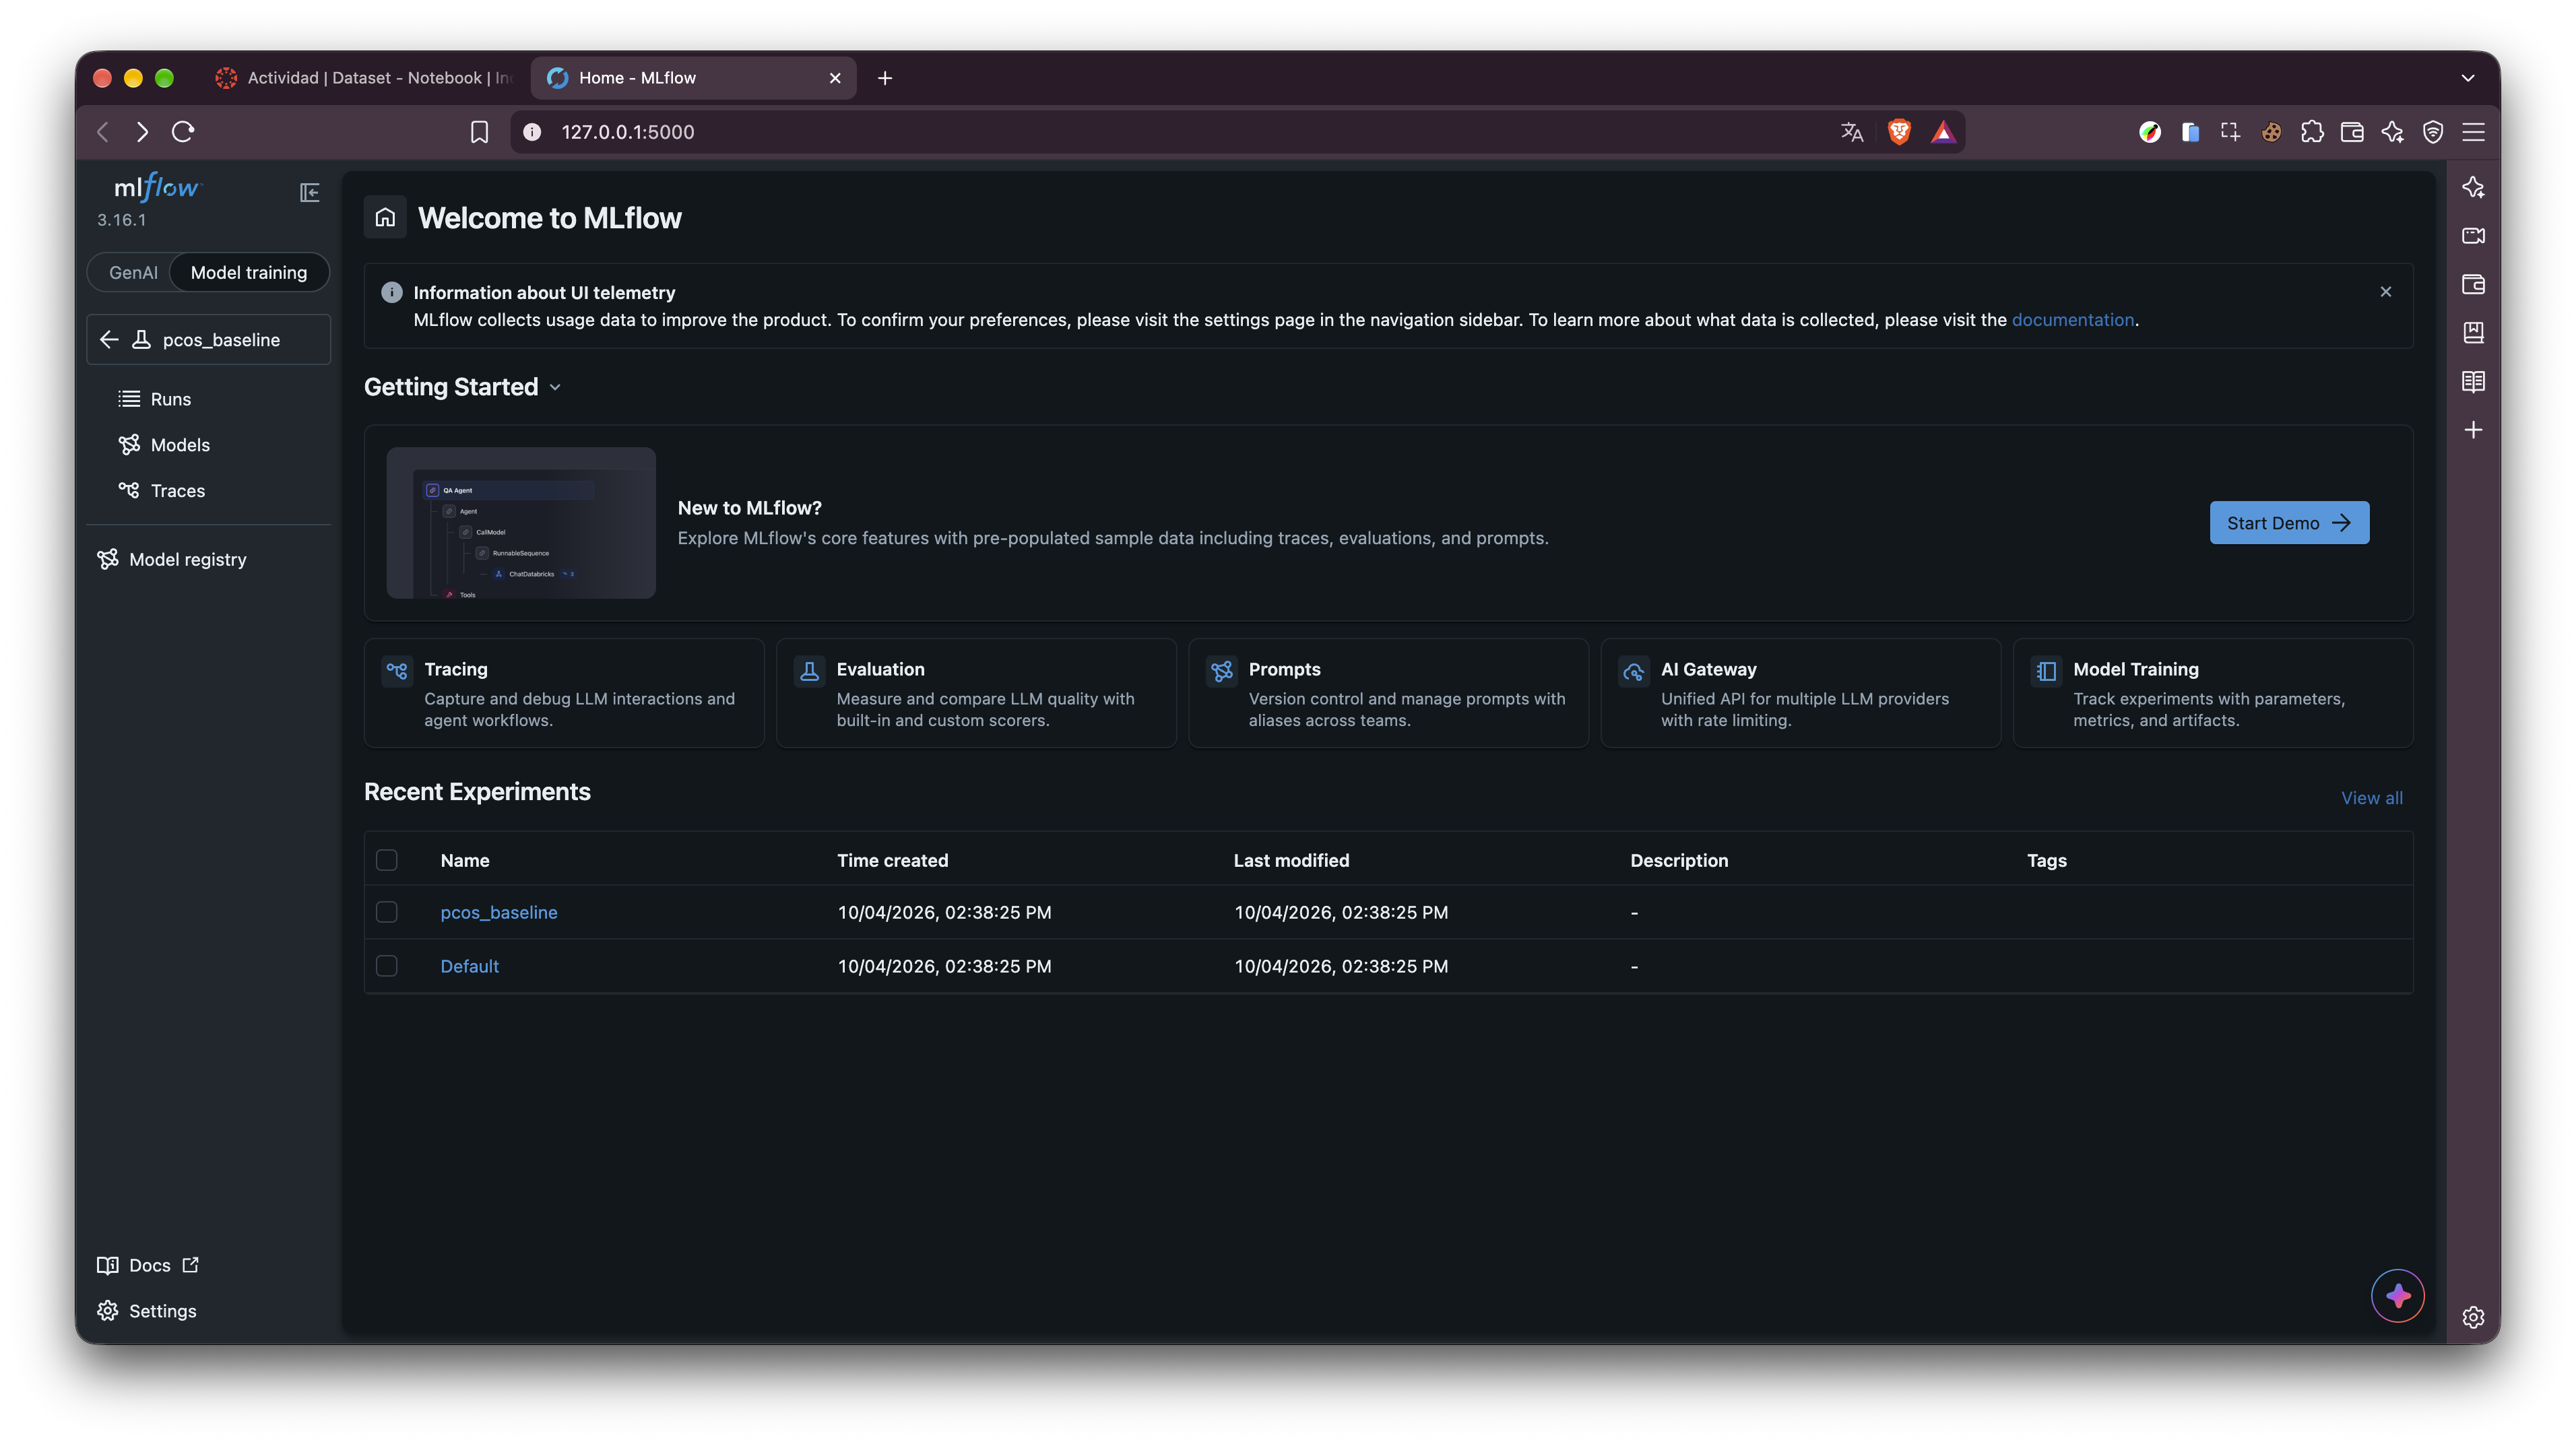

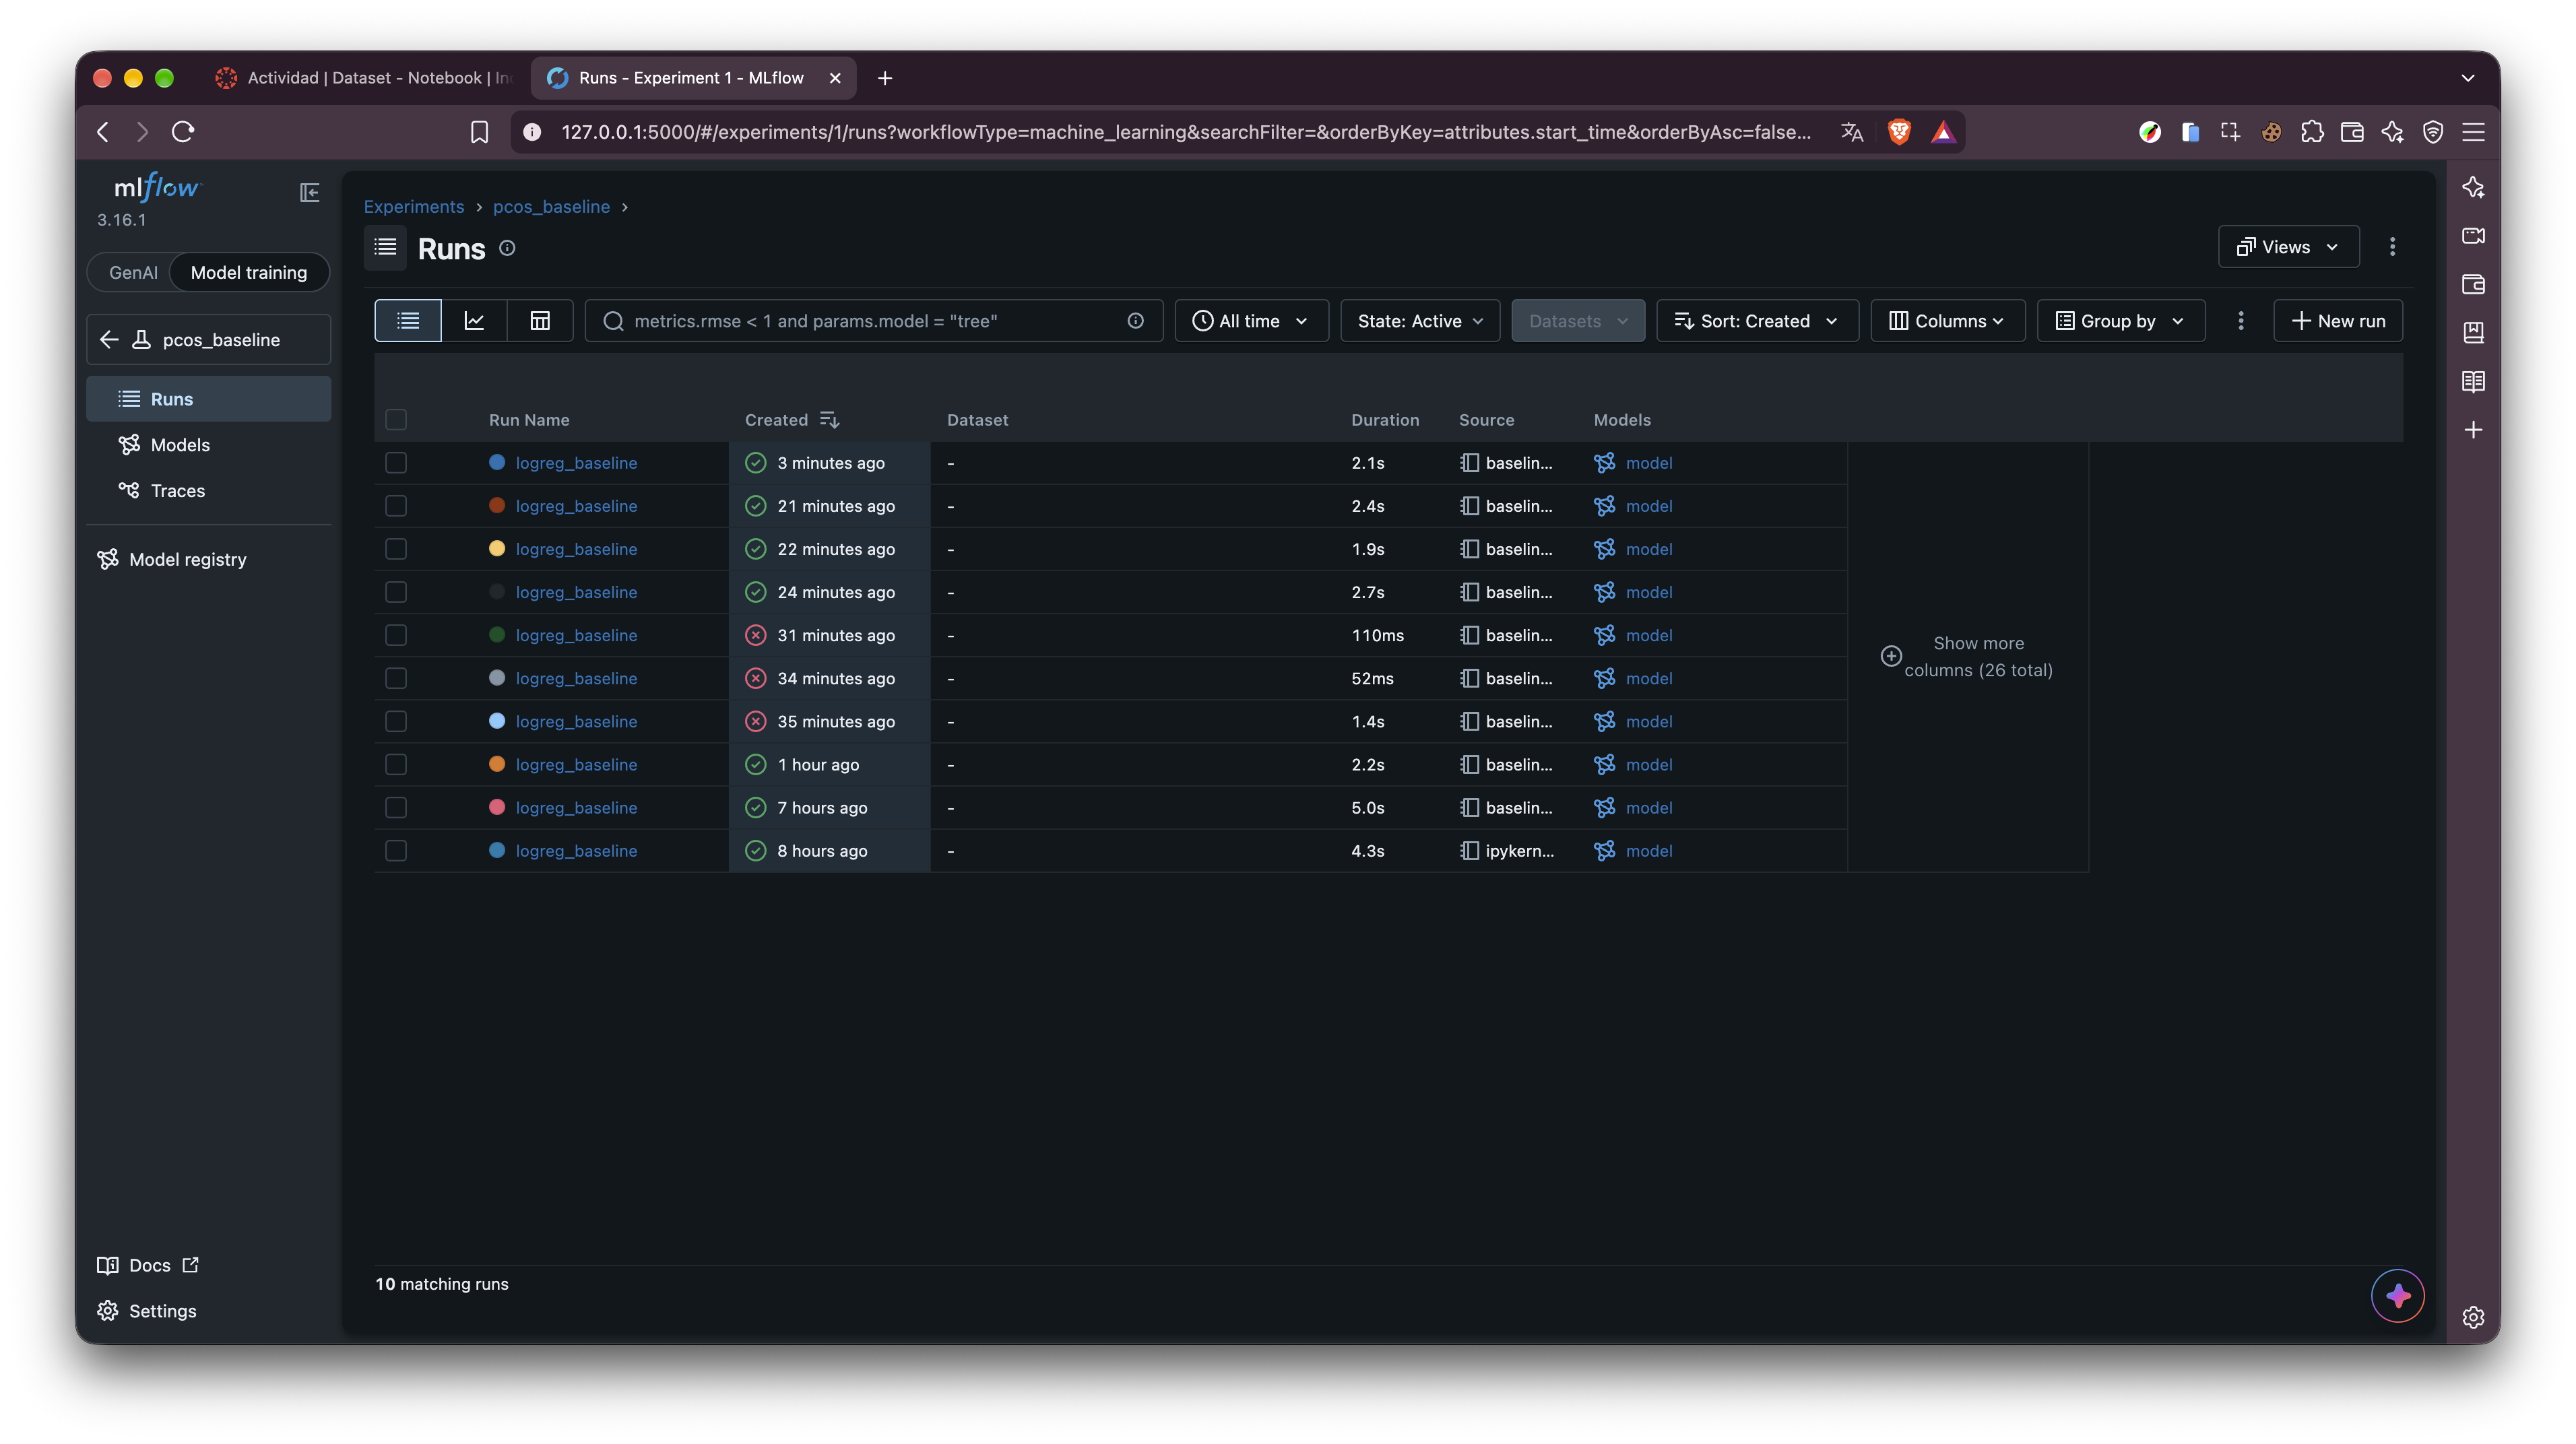

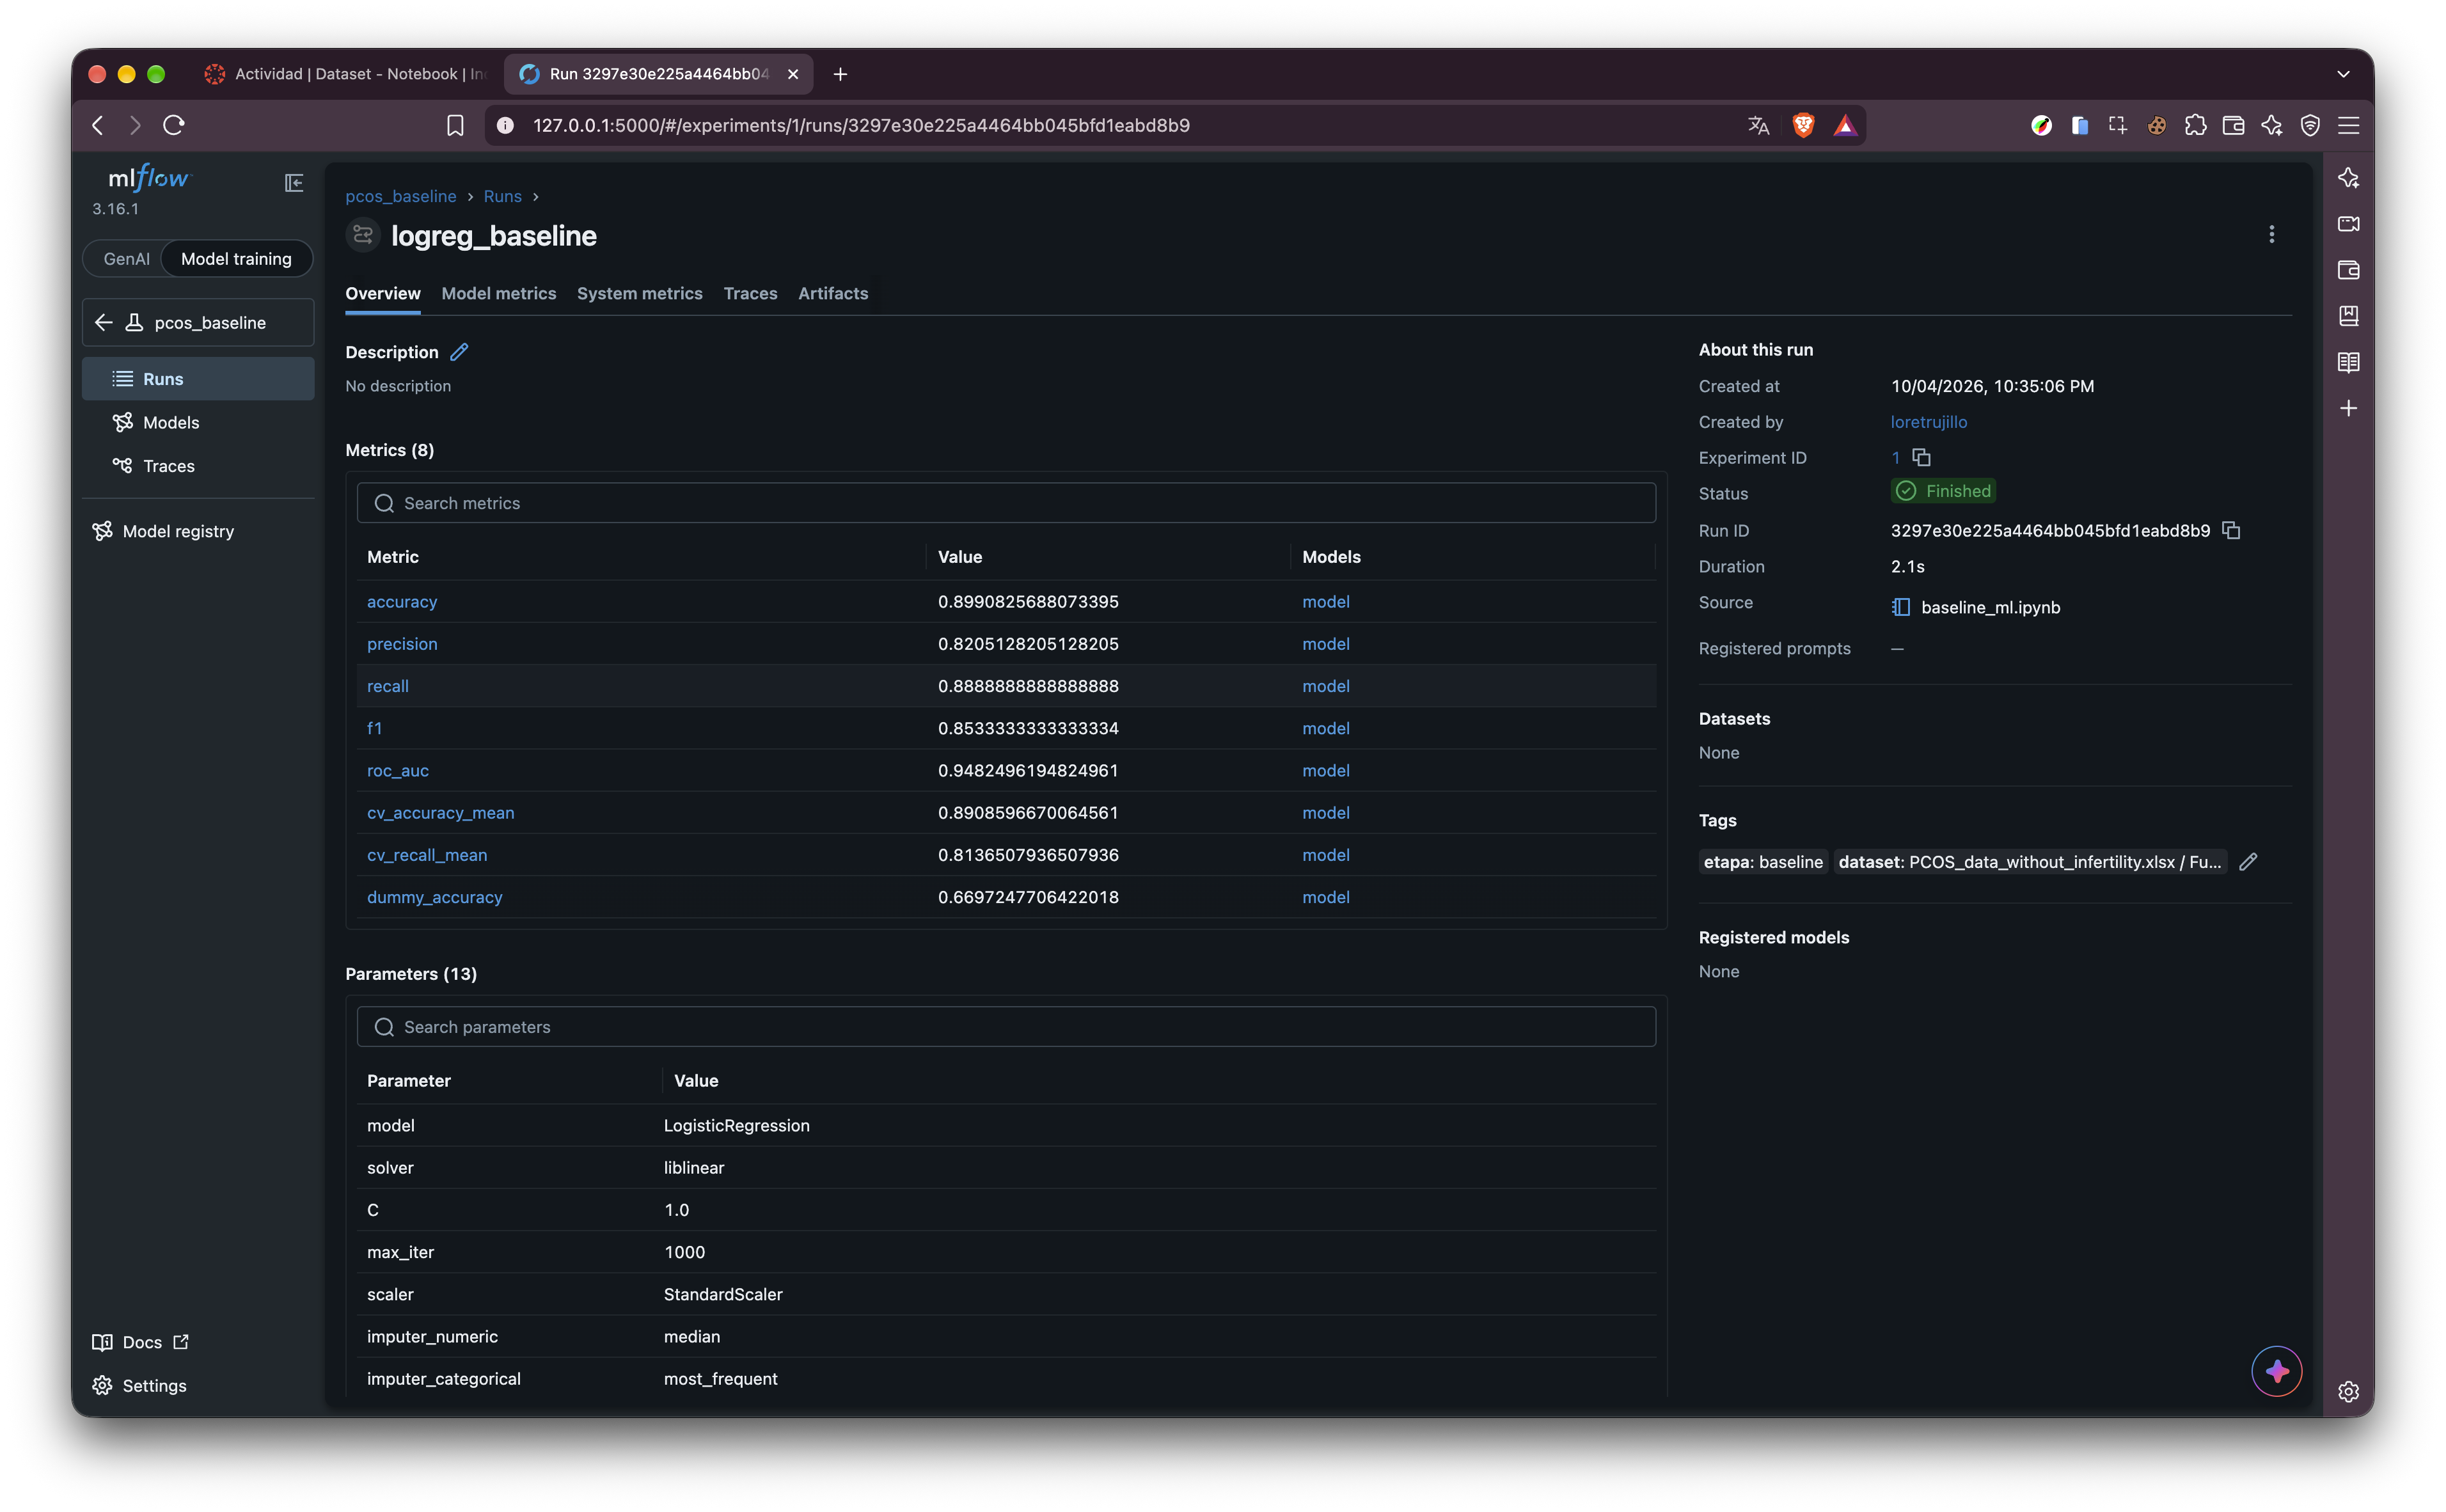

### Referencias

- Kottarathil, P. (s. f.). Polycystic ovary syndrome (PCOS) [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/prasoonkottarathil/polycystic-ovary-syndrome-pcos
- Anthropic. (2026). Claude (Sonnet 5.5) [Modelo extenso de lenguaje], utilizado para análisis del tipo de información que presenta el dataset. https://claude.ai